# SPI minority-class and label audit

This is an executed **local diagnostic report**, not a new Kaggle run or final
evaluation. Training already executed in the project `.venv`; this notebook
verifies and visualizes its saved evidence. All former-test targets are excluded
from this recovery study. The existing 300 MEDIC images were reused.

Run from `SemanticSchedulerEnd2End` using `.venv/Scripts/python.exe -m
experiments.spi_classifier_repair.build_recovery_notebook`. The existing project
dependency specification/environment is reused; no new packages are installed.
Actual versions and paths are printed below. Kaggle v20 results remain immutable.


## Actual environment and execution scope

In [1]:
print('SETUP START', flush=True)
import json, sys, platform, time, importlib.metadata
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from parameters.artifacts import Run
from experiments.spi_classifier_repair.resume_store import file_hash
ROOT = Path.cwd().resolve()
RUN = ROOT/'experiments/spi_classifier_repair/runs/minority_recovery_20261029'
REPORT_RUN = Run(RUN/'notebook_execution', {'scope':'saved-result diagnostic; no fitting/test use'})
print('Interpreter:', sys.executable, 'Python:', sys.version, 'Project:', ROOT)
print('Backend: CPU report rendering; no new encoder/VLM forward')
print('Packages:', {p:importlib.metadata.version(p) for p in ['numpy','pandas','matplotlib','torch','transformers','scikit-learn']})
print('Source:', json.loads((RUN/'source_manifest.json').read_text())['commit'])
print('Output:', REPORT_RUN.path, 'SETUP END', flush=True)


SETUP START


Interpreter: D:\Bunker\BaseCamp\WirelessCommunication\SemanticCommunication\SemanticSchedulerEnd2End\.venv\Scripts\python.exe Python: 3.12.14 (main, Aug 25 2026, 14:01:42) [MSC v.1944 64 bit (AMD64)] Project: D:\Bunker\BaseCamp\WirelessCommunication\SemanticCommunication\SemanticSchedulerEnd2End
Backend: CPU report rendering; no new encoder/VLM forward
Packages: {'numpy': '2.5.3', 'pandas': '2.3.3', 'matplotlib': '3.11.2', 'torch': '2.14.0', 'transformers': '4.57.6', 'scikit-learn': '1.9.1'}
Source: 032c23a3dafc7bfeb39a84ba55193b6b6f3a22a0
Output: D:\Bunker\BaseCamp\WirelessCommunication\SemanticCommunication\SemanticSchedulerEnd2End\experiments\spi_classifier_repair\runs\minority_recovery_20261029\notebook_execution SETUP END


## Verify inputs and class support

START 01_verify_inputs output D:\Bunker\BaseCamp\WirelessCommunication\SemanticCommunication\SemanticSchedulerEnd2End\experiments\spi_classifier_repair\runs\minority_recovery_20261029\notebook_execution


All input/source hashes match the executed recovery run.
Class counts, Low/Medium/High/Critical: {'train': [94, 17, 43, 26], 'validation': [33, 5, 20, 2]}
Former test: excluded from target parsing, fitting, selection and evaluation


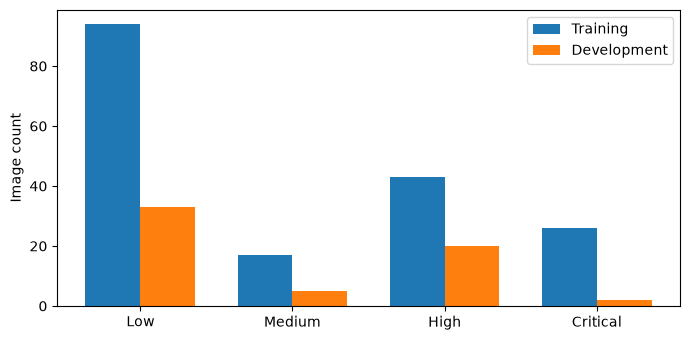

END 01_verify_inputs {'stage': '01_verify_inputs', 'status': 'complete', 'seconds': 0.2029999999795109}


In [2]:
with REPORT_RUN.stage('01_verify_inputs'):
    manifest=json.loads((RUN/'training/manifest.json').read_text())
    for key, path in [('features_sha256','comparison/clip_b32/features.npz'),('labels_sha256','labeling/labels.json'),('records_sha256','records.json')]:
        source=ROOT/'experiments/spi_classifier_repair/runs/monitor_v20/compact_outputs_v20/campaign'/path
        assert file_hash(source)==manifest[key], path
    assert file_hash(ROOT/'experiments/spi_classifier_repair/minority_recovery.py')==manifest['script_sha256']
    print('All input/source hashes match the executed recovery run.')
    print('Class counts, Low/Medium/High/Critical:', manifest['class_counts'])
    print('Former test:', manifest['old_test'])
    fig,ax=plt.subplots(figsize=(7,3.5)); names=['Low','Medium','High','Critical']; ix=np.arange(4)
    ax.bar(ix-.18,manifest['class_counts']['train'],.36,label='Training')
    ax.bar(ix+.18,manifest['class_counts']['validation'],.36,label='Development')
    ax.set_xticks(ix,names); ax.set_ylabel('Image count'); ax.legend(); fig.tight_layout()
    fig.savefig(REPORT_RUN.path/'figures/support.png',dpi=150); display(fig); plt.close(fig)


## Review label adequacy without automatic relabeling

START 02_blinded_label_audit output D:\Bunker\BaseCamp\WirelessCommunication\SemanticCommunication\SemanticSchedulerEnd2End\experiments\spi_classifier_repair\runs\minority_recovery_20261029\notebook_execution


,cases,outside_reviewer_plausible_range,immediate_harm_not_established
Low,12,0,12
Medium,12,3,12
High,12,3,9
Critical,12,6,6


Balanced48 training-image panel, AI versus AI; not a teacher-error estimate.
No labels automatically changed: True
Original AI-review mistakes and corrections: D:\Bunker\BaseCamp\WirelessCommunication\SemanticCommunication\SemanticSchedulerEnd2End\experiments\spi_classifier_repair\runs\minority_recovery_20261029\label_audit\reviewer_corrections.json


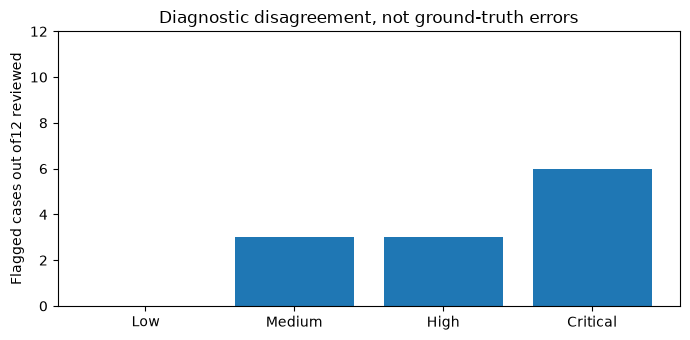

END 02_blinded_label_audit {'stage': '02_blinded_label_audit', 'status': 'complete', 'seconds': 0.2190000000409782}


In [3]:
with REPORT_RUN.stage('02_blinded_label_audit'):
    audit=json.loads((RUN/'label_audit/audit_results.json').read_text())
    assert file_hash(RUN/'label_audit/blinded_ai_review.json')==audit['review_sha256']
    table=pd.DataFrame(audit['per_teacher_class']).T
    display(table)
    print('Balanced48 training-image panel, AI versus AI; not a teacher-error estimate.')
    print('No labels automatically changed:', not audit['automatic_relabeling'])
    print('Original AI-review mistakes and corrections:', RUN/'label_audit/reviewer_corrections.json')
    fig,ax=plt.subplots(figsize=(7,3.5));ax.bar(table.index,table['outside_reviewer_plausible_range'])
    ax.set_ylim(0,12);ax.set_ylabel('Flagged cases out of12 reviewed');ax.set_title('Diagnostic disagreement, not ground-truth errors')
    fig.tight_layout();fig.savefig(REPORT_RUN.path/'figures/audit_flags.png',dpi=150);display(fig);plt.close(fig)


## Test a bounded training correction

START 03_training_only_recovery output D:\Bunker\BaseCamp\WirelessCommunication\SemanticCommunication\SemanticSchedulerEnd2End\experiments\spi_classifier_repair\runs\minority_recovery_20261029\notebook_execution


,family,training_nested_OOF_macroF1,development_macroF1,development_Medium_recall,development_Critical_recall,head_only_CPU_p50_ms,selected_config
0,balanced_logistic,0.670821,0.453426,0.2,0.5,0.1184,{'C': 10.0}
1,rf_control,0.564667,0.447005,0.0,0.5,6.5977,"{'min_samples_leaf': 2, 'tau': 0.0}"
2,rf_prior_adjustment,0.630031,0.447005,0.0,0.5,7.6590,"{'min_samples_leaf': 2, 'tau': 0.0}"


Frozen training-only family: balanced_logistic
Winning OOF score is family-selection-exposed; development is historically exposed.
No new final-test performance claim. Prior-correction final tau0 equals RF control.


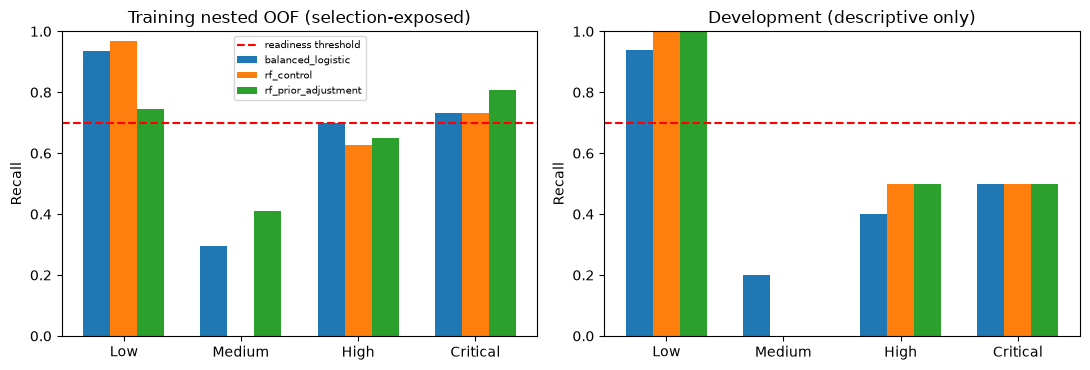

END 03_training_only_recovery {'stage': '03_training_only_recovery', 'status': 'complete', 'seconds': 0.5160000000614673}


In [4]:
with REPORT_RUN.stage('03_training_only_recovery'):
    results=json.loads((RUN/'training/results.json').read_text())
    table=pd.DataFrame([{'family':r['family'], 'training_nested_OOF_macroF1':r['nested_training_oof']['macro_f1'],
        'development_macroF1':r['validation_descriptive_only']['macro_f1'],
        'development_Medium_recall':r['validation_descriptive_only']['recall'][1],
        'development_Critical_recall':r['validation_descriptive_only']['recall'][3],
        'head_only_CPU_p50_ms':r['head_only_cpu_ms']['p50'],
        'selected_config':str(r['selected_on_training']['config'])} for r in results])
    display(table);table.to_csv(REPORT_RUN.path/'metrics/recovery_comparison.csv',index=False)
    selected=json.loads((RUN/'training/selection_frozen.json').read_text())
    print('Frozen training-only family:',selected['family'])
    print('Winning OOF score is family-selection-exposed; development is historically exposed.')
    print('No new final-test performance claim. Prior-correction final tau0 equals RF control.')
    fig,axes=plt.subplots(1,2,figsize=(11,3.8));names=['Low','Medium','High','Critical'];ix=np.arange(4)
    for j,r in enumerate(results):
        axes[0].bar(ix+(j-1)*.23,r['nested_training_oof']['recall'],.23,label=r['family'])
        axes[1].bar(ix+(j-1)*.23,r['validation_descriptive_only']['recall'],.23,label=r['family'])
    for ax,title in zip(axes,['Training nested OOF (selection-exposed)','Development (descriptive only)']):
        ax.set_xticks(ix,names);ax.set_ylim(0,1);ax.axhline(.7,color='red',ls='--',label='readiness threshold');ax.set_title(title);ax.set_ylabel('Recall')
    axes[0].legend(fontsize=7);fig.tight_layout();fig.savefig(REPORT_RUN.path/'figures/recovery_recall.png',dpi=150);display(fig);plt.close(fig)


## Verify image runtime and preserve the release boundary

In [5]:
with REPORT_RUN.stage('04_runtime_and_label_protocol'):
    parity=json.loads((RUN/'training/image_runtime_check.json').read_text())
    print('Ten real training images through encoder+head; max probability parity error:',parity['max_parity_error'])
    print('Actual bin checkpoint bytes:',parity['checkpoint_verification']['bytes'])
    print('Matches pinned upstream LFS SHA:',parity['checkpoint_verification']['local_sha256']==parity['checkpoint_verification']['hf_lfs_sha256'])
    from experiments.spi_classifier_repair.evidence_priority import PROMPT_SHA256,PROTOCOL
    print('Evidence-first teacher candidate:',PROTOCOL,PROMPT_SHA256)
    print('Candidate prompt/parser implemented and unit-tested; NOT yet run as a VLM or accepted as a labeling teacher.')
    receipt=json.loads((RUN/'training/bundle/readiness.json').read_text())
    assert receipt['runtime_promotion_allowed'] is False
    print('Research bundle:',RUN/'training/bundle','Runtime promotion:',receipt['runtime_promotion_allowed'])
    print('No full parameter cache launched. Unknown remains unavailable, not a fabricated Low label.')


START 04_runtime_and_label_protocol output D:\Bunker\BaseCamp\WirelessCommunication\SemanticCommunication\SemanticSchedulerEnd2End\experiments\spi_classifier_repair\runs\minority_recovery_20261029\notebook_execution


Ten real training images through encoder+head; max probability parity error: 1.3733406446503338e-06
Actual bin checkpoint bytes: 605247071
Matches pinned upstream LFS SHA: True
Evidence-first teacher candidate: spi_evidence_first_candidate_v2 18bcbcec102dad5b20b4230e707e43556cf2c26024a33aba269c9ef515507366
Candidate prompt/parser implemented and unit-tested; NOT yet run as a VLM or accepted as a labeling teacher.
Research bundle: D:\Bunker\BaseCamp\WirelessCommunication\SemanticCommunication\SemanticSchedulerEnd2End\experiments\spi_classifier_repair\runs\minority_recovery_20261029\training\bundle Runtime promotion: False
No full parameter cache launched. Unknown remains unavailable, not a fabricated Low label.
END 04_runtime_and_label_protocol {'stage': '04_runtime_and_label_protocol', 'status': 'complete', 'seconds': 0.01500000013038516}


## Decision

The current SPI classifier remains unready. The training correction prevents a
zero-recall candidate from silently winning on average score, but does not solve
minority recognition. The AI audit flags label problems and also exposes reviewer
fallibility. Class-balanced disagreement is neither human truth nor calibrated
teacher error. Do not clear the diagnostic gate or relabel images from agreement.

Keep four classes and the current parameter/header contract. Before another final
training run: verify evidence-first labels on resolved image-level cases, reserve
adequately supported unexposed groups, and then refit the fixed compact head.
Current300 cannot be made a fresh final test by reshuffling them.

The prior-correction hypothesis was motivated by [Menon et al., ICLR2021](https://research.google/pubs/long-tail-learning-via-logit-adjustment/).
It was tested on an already balanced forest and was **not retained** in the final
fit; no paper-level guarantee transfers to that forest experiment.

Reproduce fitting in a **new output directory** with `python -m
experiments.spi_classifier_repair.minority_recovery --features <verified CLIP
features.npz> --records <v20 records.json> --labels <v20 labels.json> --output
<new directory>`. This notebook reuses saved fitting results; it does not refit.
